<a href="https://colab.research.google.com/github/tselane2110/Urdu-BinarySarcasmDetection/blob/main/TF_IDF_logisticRegressionModel.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## 0. Cloning into Git Repo

In [1]:
# cloning into Git Repo
!git clone https://github.com/tselane2110/NaturalLanguageProcessing

fatal: destination path 'NaturalLanguageProcessing' already exists and is not an empty directory.


In [2]:

%cd /content/NaturalLanguageProcessing

/content/NaturalLanguageProcessing


In [3]:
%ls

corpus1.txt            TF_IDF_logisticRegressionModel.ipynb
projectGuidelines.pdf  urdu_sarcastic_dataset.csv
README.md


## 1. Data Analysis and Preprocessing

In [4]:
import re
import matplotlib.pyplot as plt
import pandas as pd

pd.set_option('display.max_colwidth', None)   # show full column width
df = pd.read_csv('urdu_sarcastic_dataset.csv')
df.head()

,urdu_text,is_sarcastic,Unnamed: 2,Unnamed: 3,Unnamed: 4,Unnamed: 5,Unnamed: 6,Unnamed: 7
0,🤣😂😂 ہو لینے دے میری شادی فسادن ٹھیک ہے کوجی نہیں چاہیے 😐😐😐🤣,1.0,NaN,NaN,NaN,NaN,NaN,NaN
1,چل مہمانوں میں کھانا سرو کر چڑیل چاچی نوں دسدی آں میں😂😂,1.0,NaN,NaN,NaN,NaN,NaN,NaN
2,کامران خان آپکی دن بھریہ زمہ داری لگائی گئی اپوزیشن کی کردار کشی اوراس پربھونکناہےآپ خوشامدگری وچاپلوسی سےاورکتنی دولت کماناچاہتےہیں موٹرسائیکل سےپیجارو پراڈو تک کےسفرمیں ضمیرکی لاش سےاٹھتی بدبوآپ کی ناک بند نہیں کرتی ہے 🙏نوٹ آپ سب سےالتجاگزارش ہےہمیں بھی فالوکریں شکریہ,0.0,NaN,NaN,NaN,NaN,NaN,NaN
3,نہیں پائین 😎,0.0,NaN,NaN,NaN,NaN,NaN,NaN
4,`` مراد علی شاہ کے بھیس میں ڈی جی آئی ایس آئی تھے '' حامد میر😁,1.0,NaN,NaN,NaN,NaN,NaN,NaN


In [5]:
df.columns

Index(['urdu_text', 'is_sarcastic', 'Unnamed: 2', 'Unnamed: 3', 'Unnamed: 4',
       'Unnamed: 5', 'Unnamed: 6', 'Unnamed: 7'],
      dtype='object')

### i. Not Including Unnecessary Columns

In [6]:
# not using the extra unimportant columns

df = df.iloc[:, :-6]
df.head(10)

,urdu_text,is_sarcastic
0,🤣😂😂 ہو لینے دے میری شادی فسادن ٹھیک ہے کوجی نہیں چاہیے 😐😐😐🤣,1.0
1,چل مہمانوں میں کھانا سرو کر چڑیل چاچی نوں دسدی آں میں😂😂,1.0
2,کامران خان آپکی دن بھریہ زمہ داری لگائی گئی اپوزیشن کی کردار کشی اوراس پربھونکناہےآپ خوشامدگری وچاپلوسی سےاورکتنی دولت کماناچاہتےہیں موٹرسائیکل سےپیجارو پراڈو تک کےسفرمیں ضمیرکی لاش سےاٹھتی بدبوآپ کی ناک بند نہیں کرتی ہے 🙏نوٹ آپ سب سےالتجاگزارش ہےہمیں بھی فالوکریں شکریہ,0.0
3,نہیں پائین 😎,0.0
4,`` مراد علی شاہ کے بھیس میں ڈی جی آئی ایس آئی تھے '' حامد میر😁,1.0
5,قابل اعتبار ہی اکثر قاتل اعتبار ہوتے ہیں 💔🔥,1.0
6,انساں کو تھکا دیتا ہے سوچوں کا سفر بھی ... 🍁🥀,0.0
7,حامد میر صاحب ویلڈن👏😊,0.0
8,یار وچارہ ویلا ہوندا ہے اس آرے لگا ہویا ہے😂😂 تسی تے پکے نجومی ہو اسی منندے ہاں,1.0
9,یہ سمجھتے ہیں سارا پاکستان بیوقوف ھے 😂😂😂,1.0


In [7]:
# renaming the text columns
df = df.rename(columns={'urdu_text': 'text'})
df.head(2)

,text,is_sarcastic
0,🤣😂😂 ہو لینے دے میری شادی فسادن ٹھیک ہے کوجی نہیں چاہیے 😐😐😐🤣,1.0
1,چل مہمانوں میں کھانا سرو کر چڑیل چاچی نوں دسدی آں میں😂😂,1.0


### ii. Dropping NaN rows

In [8]:
# finding NaN rows

df.isna().sum()

,0
text,105
is_sarcastic,56


In [9]:
# dropping all NaN rows

df = df.dropna()

In [10]:
df.head(2)

,text,is_sarcastic
0,🤣😂😂 ہو لینے دے میری شادی فسادن ٹھیک ہے کوجی نہیں چاہیے 😐😐😐🤣,1.0
1,چل مہمانوں میں کھانا سرو کر چڑیل چاچی نوں دسدی آں میں😂😂,1.0


In [11]:
len(df)

19955

### iii. Deduplicating Dataset

In [12]:
df.duplicated().sum()

np.int64(3545)

In [13]:
# deleting all completely identical rows
df.drop_duplicates(inplace=True)

In [14]:
19955-3545

16410

In [15]:
len(df)

16410

In [16]:
df['text'].nunique()

15813

In [17]:
new_df = df.copy()
new_df['is_sarcastic'] = new_df['is_sarcastic'].astype(int) # fixing datatype of the target label
new_df['text_clean'] = (new_df['text'].str.lower()
                             .str.strip()
                             .str.replace(r'\s+', ' ', regex=True)) # normalizing text

In [18]:
new_df.drop_duplicates(inplace=True)

In [19]:
len(new_df)

16410

In [20]:
new_df.nunique()

,0
text,15813
is_sarcastic,2
text_clean,15213


In [21]:
new_df.drop(columns=['text'], inplace=True)

In [22]:
len(new_df)

16410

In [23]:
new_df.drop_duplicates(inplace=True)

In [24]:
len(new_df)

15859

In [25]:
new_df.nunique()

,0
is_sarcastic,2
text_clean,15213


In [26]:
len(new_df) - new_df['text_clean'].nunique()

646

#### Analysis-1

* We have total 15859 rows out of which 15213 have unique text rows.
* This means that we have 646 "unique-text-rows" with AT MOST one duplicate.

In [27]:
# counting the occurence of each text against each target label
counts = (new_df.groupby('text_clean')['is_sarcastic'].value_counts()
            .unstack(fill_value=0)
            .reindex(columns=[0, 1], fill_value=0))

new_df['count_label_0'] = new_df['text_clean'].map(counts[0]).fillna(0).astype(int)
new_df['count_label_1'] = new_df['text_clean'].map(counts[1]).fillna(0).astype(int)

In [28]:
new_df.nunique()

,0
is_sarcastic,2
text_clean,15213
count_label_0,2
count_label_1,2


In [29]:
new_df['count_label_0'].unique()

array([1, 0])

In [30]:
new_df['count_label_1'].unique()

array([1, 0])

In [31]:
to_drop = []
for index, row in new_df.iterrows():
    if (row['count_label_0'] < row['count_label_1']):
        new_df.at[index, 'is_sarcastic'] = 1
    elif (row['count_label_0'] > row['count_label_1']):
        new_df.at[index, 'is_sarcastic'] = 0
    else:
      to_drop.append(index)

dropped_duplicates = new_df.loc[to_drop]
unique_rows = dropped_duplicates.drop_duplicates(
    subset=['text_clean']
)

print(f"The number of duplicate rows with equal count for both target labels: {len(to_drop)}.")
print(f"The count of unique-text rows within the above mentioned duplicates: {len(unique_rows)}.")

new_df.drop(to_drop, inplace = True)

The number of duplicate rows with equal count for both target labels: 1292.
The count of unique-text rows within the above mentioned duplicates: 646.


#### Analysis-2
* It turns out that those 646 unique-text-rows had one duplicate of itself and there was a tie on the count of both target labels for each of these rows.
* Hence we dropped 2 times 646 rows == 1292 duplicates.

In [32]:
len(dropped_duplicates['text_clean'].unique())

646

In [33]:
dropped_duplicates['text_clean'].value_counts()

,count
text_clean,
وہ پوچھنا یہ تھا چوں کہ مریم اور بلاول اب بہن بھائی بن گئے ہیں تو بلاول کو پٹواریوں کا ماموں کہا جاسکتا ہے 😂😂,2
🤣😂😂 ہو لینے دے میری شادی فسادن ٹھیک ہے کوجی نہیں چاہیے 😐😐😐🤣,2
چل مہمانوں میں کھانا سرو کر چڑیل چاچی نوں دسدی آں میں😂😂,2
کامران خان آپکی دن بھریہ زمہ داری لگائی گئی اپوزیشن کی کردار کشی اوراس پربھونکناہےآپ خوشامدگری وچاپلوسی سےاورکتنی دولت کماناچاہتےہیں موٹرسائیکل سےپیجارو پراڈو تک کےسفرمیں ضمیرکی لاش سےاٹھتی بدبوآپ کی ناک بند نہیں کرتی ہے 🙏نوٹ آپ سب سےالتجاگزارش ہےہمیں بھی فالوکریں شکریہ,2
`` مراد علی شاہ کے بھیس میں ڈی جی آئی ایس آئی تھے '' حامد میر😁,2
...,...
پتہ نہیں کیا ہورہا ہے سی سی کی بورڈ کو زنگ لگ گیا ہے😭😭,2
اب بس بھی کرو بیچارے کی پہلے ہی دو بیویاں ہیے کیا اپ نے تیسری کے لیے ٹرائ کرنا ہے 😜,2
😍عشق جب تم کو راس آۓ گا 💔زخم کھاٶ گے 😊مُسکراٶ گے,2


In [34]:
len(new_df)

14567

In [35]:
new_df.duplicated().sum()

np.int64(0)

In [36]:
new_df['text_clean'].duplicated().sum()

np.int64(0)

In [37]:
new_df.columns

Index(['is_sarcastic', 'text_clean', 'count_label_0', 'count_label_1'], dtype='object')

In [38]:
new_df.drop(columns=['count_label_0', 'count_label_1'], inplace=True)
new_df.columns

Index(['is_sarcastic', 'text_clean'], dtype='object')

In [39]:
new_df.rename(columns={'text_clean': 'text'}, inplace=True)

In [40]:
df = new_df.reset_index(drop=True)
df.columns, len(df)

(Index(['is_sarcastic', 'text'], dtype='object'), 14567)

### iv. Identifying Class Distribution

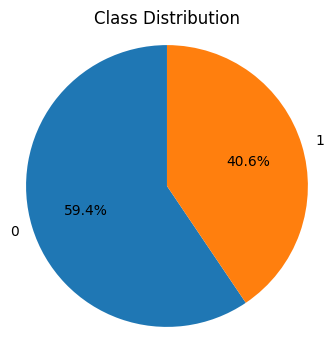

In [41]:
import matplotlib.pyplot as plt

# Assuming y is your target column (pandas Series or array)
counts = df['is_sarcastic'].value_counts()

# Pie chart
plt.figure(figsize=(4, 4))
plt.pie(counts, labels=counts.index, autopct='%1.1f%%', startangle=90)
plt.title('Class Distribution')
plt.axis('equal')
plt.show()

### v. Detecting and Analyzing Hashtag Content

In [42]:
import re
from collections import Counter

# extract all hashtags (lowercased) across all rows
hashtags = df['text'].str.findall(r'#(\w+)', flags=re.IGNORECASE)

# flatten and count
counter = Counter(
    tag.lower()
    for tags in hashtags
    for tag in tags
)

hashtag_counts = dict(counter)

In [43]:
len(hashtag_counts)

551

In [44]:
hashtag_df = pd.DataFrame(
    hashtag_counts.items(),
    columns=['hashtag', 'count']
)

In [45]:
hashtag_df = hashtag_df.sort_values('count', ascending=False).reset_index(drop=True)

In [46]:
hashtag_df.head(551)

,hashtag,count
0,sarcasm,381
1,طنز,150
2,sarcastic,56
3,آئےناں_کنٹینرتے,31
4,مزاح,21
...,...,...
546,mamtabanerjee,1
547,congress,1
548,ncp,1
549,tmc,1


### vi. Text Cleaning

* Removed the following content:

  * URLs
  * @mentions
  * Hashtag contents that could leak the target label, for example #sarcasm, #sarcastic, #طنز etc. These were selected after carefully analyzing all hashtags that were present in the originally given dataset.

* Added \<EMPHASIS\>\<\EMPHASIS\> around the bold text
* Normalized Whitespaces
* Used `wordsegment` library to segment out the joint english words like goodmorningpakistan or HelloWorld would be converted to "good morning pakistan" and "hello world"
* Demojized emojis continue to keep the underscore in their name_tag


In [47]:
!pip install emoji

In [48]:
!pip install wordsegment

#### a. Helper Functions

In [49]:
!pip install wordninja

In [50]:
import re
import emoji
import pandas as pd
import string
import unicodedata
from wordsegment import load, segment
import wordninja

load() # Load the English dictionaries for segmentation

URL_PATTERN = re.compile(r'(?:https?://|www\.)[^\s]+(?<![.,;!?؟۔،\)"\'])', re.IGNORECASE)
MENTION_PATTERN = re.compile(r'@[A-Za-z0-9_]+')
LEAKY = [r"sarcasm\w*", r"sarcastic\w*", r"beingsarcastic",
         r"satire\w*", r"racistjokes",
         r"طنزومزاح", r"طنز"]                 # only standard forms now
SARCASM_PATTERN = re.compile(r"#?(?:" + "|".join(LEAKY) + r")(?!\w)", re.IGNORECASE)
UNICODE_BOLD = re.compile(r'[\U0001D400-\U0001D7FF]+')

# Function to extract emojis into a new column and remove them from text
def extract_and_remove_emojis(text):
    text = str(text)
    # Find all emojis in the text
    found_emojis = "".join([char for char in text if char in emoji.EMOJI_DATA])
    # Remove emojis from the text
    cleaned_text = "".join(
        [char for char in text if char not in emoji.EMOJI_DATA]
    )
    return cleaned_text, found_emojis

# Function to process the hashtags with important content
def process_advanced_hashtags(text):
    # Find all hashtags
    hashtags = re.findall(r'#\w+', text)

    for tag in hashtags:
        clean_tag = tag.replace('#', '')

        # Check if it contains Urdu characters
        if re.search(r'[\u0600-\u06FF]', clean_tag):
            # It's Urdu: just remove the hash, leave it joined
            text = text.replace(tag, clean_tag)
        else:
            # It's English/Roman: Segment it using the library
            # segment() handles both CamelCase and all-lowercase brilliantly
            split_words = " ".join(segment(clean_tag))
            text = text.replace(tag, split_words)

    return text

def separate_english_words(text):
    # This regex looks for any continuous string of English alphabets
    # The lambda function takes the match, splits it using wordninja, and joins with spaces
    return re.sub(r'[a-zA-Z]+', lambda match: ' '.join(wordninja.split(match.group(0))), text)

def handle_bold_text(text):

    # 1. *word* or **word** → <EMPHASIS>word<\EMPHASIS>
    text = re.sub(r'\*{1,2}([^*]+?)\*{1,2}', r'<EMPHASIS>\1</EMPHASIS>', text)

    # 2. Unicode bold runs → <EMPHASIS>...</EMPHASIS>
    text = UNICODE_BOLD.sub(lambda m: f"<EMPHASIS>{m.group(0)}</EMPHASIS>", text)

    return text

#### b. Text Preprocessing Pipeline

In [51]:
def text_preprocessing_pipeline(text):
    text = str(text)

    # adding <EMPHASIS></EMPHASIS> tags around bold words
    text = handle_bold_text(text)

    # normalizing arabic/urdu script
    text = unicodedata.normalize('NFKC', text)

    # Replacing URLs with the <URL> tags
    text = URL_PATTERN.sub('<URL>', text)

    # Removing all @mentions
    text = MENTION_PATTERN.sub('<USER>' , text)

    # Remove the terms that could risk leaking the target label
    text = SARCASM_PATTERN.sub("", text)

    # Preprocessing of the hashtags with the content we wanna keep
    text = process_advanced_hashtags(text)

    # replacing any remaining # symbols with whitespaces
    text = text.replace('#', '')

    # replacing all underscores with a white space
    text = text.replace('_', ' ')

    # Standardizing Urdu Punctuation to English equivalents
    text = text.replace('؟', '?').replace('۔', '.').replace('،', ',').replace('؛', ';').replace('٪', '%')

    # Remove hidden ZWNJ characters to prevent duplicate vocabulary tokens
    text = text.replace('\u200c', '')

    # Demojize Emojis INLINE
    # Converts 🙄 to "[rolling_eyes]" so the model reads it exactly where it occurred.
    text = emoji.demojize(text, delimiters=(" <", "> "))

    # converting all english text to lower-case
    text = text.lower()

    # separating lower-cased english words where applicable
    text = separate_english_words(text)

    # Find all ?, ., ! marks
    found_punc = "".join(re.findall(r"[?.!]", text))

    # normalizing whitespace
    text = re.sub(r"\s+", " ", text).strip()

    # Remove all sorts of punctuation from the text
    # string.punctuation covers all standard symbols

    punct_to_remove = string.punctuation.replace("\\", "").replace("<", "").replace(">", "")

    translator = str.maketrans("", "", punct_to_remove)
    cleaned_text = text.translate(translator)

    return cleaned_text, found_punc

#### c. Function for One-Hot Encoding Each Column

In [52]:
from collections import Counter

def expand_element_counts(df, column_name):
    """
    Parses a column containing strings.
    - Preserves <tags> as whole unique elements (e.g., '<user_id>').
    - Treats all other non-space characters as individual elements.
    """
    def extract_and_tokenize(text):
        if pd.isna(text):
            return []

        # The change is here: [^<>\s] no longer has a '+' at the end.
        # This forces it to grab individual characters instead of chunks.
        return re.findall(r'<[^>]+>|[^<>\s]', str(text))

    # 1. Tokenize the string and count occurrences for each row
    counts_list = df[column_name].apply(lambda x: Counter(extract_and_tokenize(x))).tolist()

    # 2. Feed directly into a DataFrame constructor
    # 3. Fill missing elements with 0 and convert to integers, keeping original index
    counts_df = pd.DataFrame(counts_list, index=df.index).fillna(0).astype(int)

    # 4. Join the new columns back to the original DataFrame
    return pd.concat([df, counts_df], axis=1)

### vii. Emoji Count Analysis

In [53]:
df_emoji = df.copy()
df_emoji["text_no_emoji"], df_emoji["emojis"] = zip(*df_emoji["text"].apply(extract_and_remove_emojis))

In [54]:
df_emoji.columns

Index(['is_sarcastic', 'text', 'text_no_emoji', 'emojis'], dtype='object')

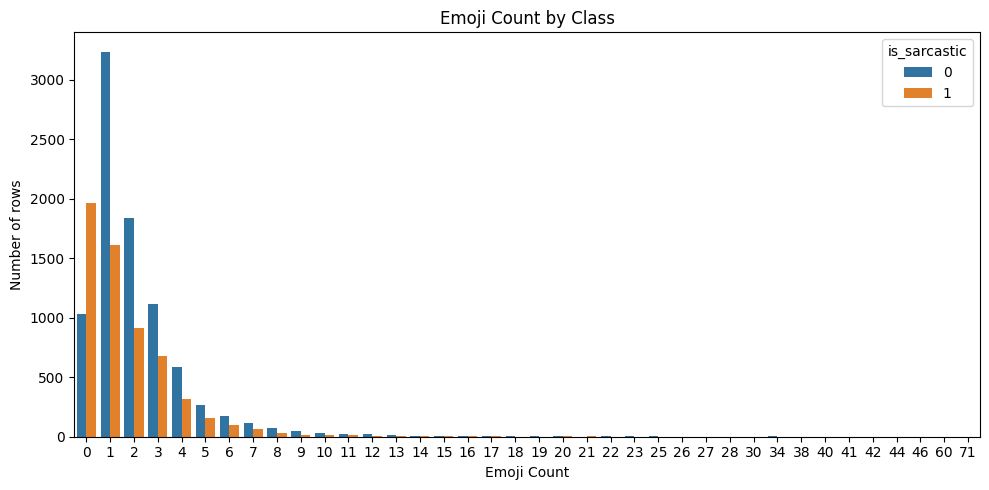

In [55]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

# df_emoji has an emoji-only column, e.g. 'emojis'
df_emoji['emoji_count'] = df_emoji['emojis'].fillna('').astype(str).apply(len)

# plot
plt.figure(figsize=(10, 5))
sns.countplot(data=df_emoji, x='emoji_count', hue='is_sarcastic')
plt.title('Emoji Count by Class')
plt.xlabel('Emoji Count')
plt.ylabel('Number of rows')
plt.tight_layout()
plt.show()

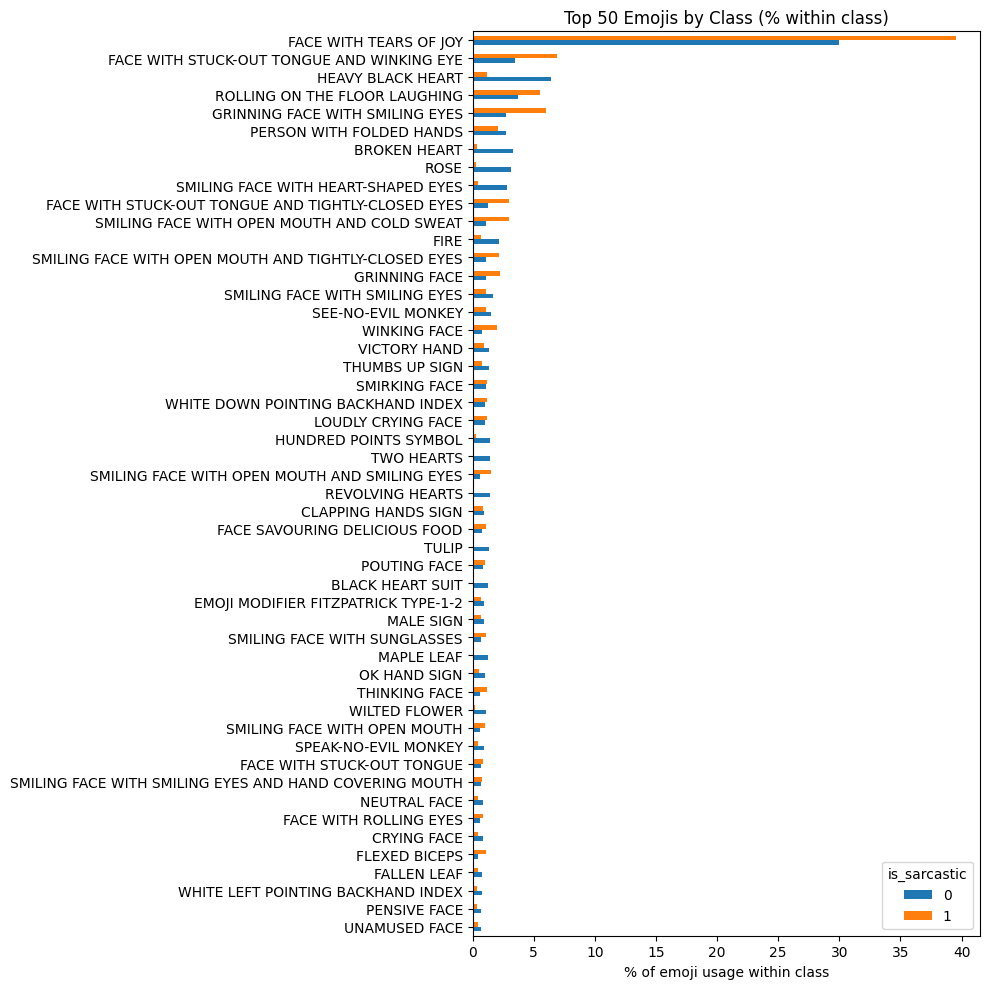

In [56]:
import matplotlib
matplotlib.rcdefaults()          # reset font config

import matplotlib.pyplot as plt
import pandas as pd
import unicodedata

# 1. Explode
exploded = df_emoji[['emojis', 'is_sarcastic']].copy()
exploded['emojis'] = exploded['emojis'].fillna('').astype(str)
exploded = exploded.assign(emoji=exploded['emojis'].apply(list)).explode('emoji')
exploded = exploded[exploded['emoji'].str.strip() != '']

# 2. Counts per class
counts = exploded.groupby(['emoji', 'is_sarcastic']).size().unstack(fill_value=0)

# 3. Top N by total
top_n = 50
counts['total'] = counts.sum(axis=1)
top = counts.sort_values('total', ascending=False).head(top_n).drop(columns='total')

# 4. Normalize within class
top_pct = top / top.sum(axis=0) * 100

# 5. Emoji -> Unicode name
def emoji_label(e):
    try:
        return unicodedata.name(e)
    except ValueError:
        return f'U+{ord(e):04X}'

top_pct.index = [emoji_label(e) for e in top_pct.index]

# 6. Plot
top_pct[::-1].plot(kind='barh', figsize=(10, 10))
plt.title(f'Top {top_n} Emojis by Class (% within class)')
plt.xlabel('% of emoji usage within class')
plt.tight_layout()
plt.show()

### viii. Dataset-1 (with individual emojis and punctuations as a separate features)

Contains the following columns:

* `is_sarcastic`
* `text` without emojis and punctuations
* `word_count` - added after preprocessing

And the following columns contain the count of each element in a row:

* `!`
* `?`
* `.`
* A separate column for each demojized emoji (**591 columns**)

In [57]:
df1 = df.copy()

# Apply Emoji extraction
df1["text_no_emoji"], df1["emojis"] = zip(*df1["text"].apply(extract_and_remove_emojis))

# Apply Punctuation extraction on the emoji-cleaned text (or original text)
df1["cleaned_text"], df1["punctuations"] = zip(
    *df1["text_no_emoji"].apply(text_preprocessing_pipeline)
)

# Clean up intermediate column if you want
df1 = df1.drop(columns=["text_no_emoji"])
# Dropping the uncleaned `text` column
df1.drop(columns='text', inplace=True)
# Renaming `cleaned_text` to `text`
df1 = df1.rename(columns={'cleaned_text': 'text'})
# output
df1.columns

Index(['is_sarcastic', 'emojis', 'text', 'punctuations'], dtype='object')

In [58]:
# Changes 🔥 from :fire: to <fire>
df1['demojized'] = df1['emojis'].apply(
    lambda x: emoji.demojize(x, delimiters=("<", ">")) if pd.notna(x) else x
)
df1.drop(columns=['emojis'], inplace = True)

In [59]:
df1 = expand_element_counts(df1, 'demojized')
df1 = expand_element_counts(df1, 'punctuations')
df1.drop(columns=['demojized', 'punctuations'], inplace = True)
df1.columns

Index(['is_sarcastic', 'text', '<smiling_face_with_sunglasses>',
       '<maple_leaf>', '<wilted_flower>', '<clapping_hands>',
       '<smiling_face_with_smiling_eyes>', '<face_with_tears_of_joy>',
       '<grinning_squinting_face>', '<face_with_rolling_eyes>',
       ...
       '<person_running_medium-light_skin_tone>', '<sparkle>', '<brain>',
       '<ATM_sign>', '<coin>', '<money_bag>', '<white_cane>', '.', '?', '!'],
      dtype='object', length=587)

#### Emoji List

In [60]:
emoji_list = df1.columns.tolist()
not_emojis = ['.', '!', '?', 'word_count', 'text_length', 'is_sarcastic', 'text']
emoji_list = [item for item in emoji_list if item not in not_emojis]
len(emoji_list)

582

In [61]:
df1.head(2)

,is_sarcastic,text,<smiling_face_with_sunglasses>,<maple_leaf>,<wilted_flower>,<clapping_hands>,<smiling_face_with_smiling_eyes>,<face_with_tears_of_joy>,<grinning_squinting_face>,<face_with_rolling_eyes>,...,<person_running_medium-light_skin_tone>,<sparkle>,<brain>,<ATM_sign>,<coin>,<money_bag>,<white_cane>,.,?,!
0,0,نہیں پائین,1,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
1,0,انساں کو تھکا دیتا ہے سوچوں کا سفر بھی,0,1,1,0,0,0,0,0,...,0,0,0,0,0,0,0,3,0,0


In [62]:
# Confirming that no hashtags are remaining

# Filter rows where the 'text' column contains a hashtag
hashtag_rows_df1 = df1[df1["text"].str.contains("#", na=False)]

# See how many rows have hashtags
print(f"Total rows with hashtags: {len(hashtag_rows_df1)}")

Total rows with hashtags: 0


#### Adding word-count feature

In [63]:
# Whitespace Splitting
# Splits by any whitespace (spaces, tabs, newlines).
# Works perfectly for both English and Urdu.
# ---------------------------------------------------------
df1['word_count'] = df1['text'].str.split().str.len().fillna(0).astype(int)

#### Text-Length Statistics

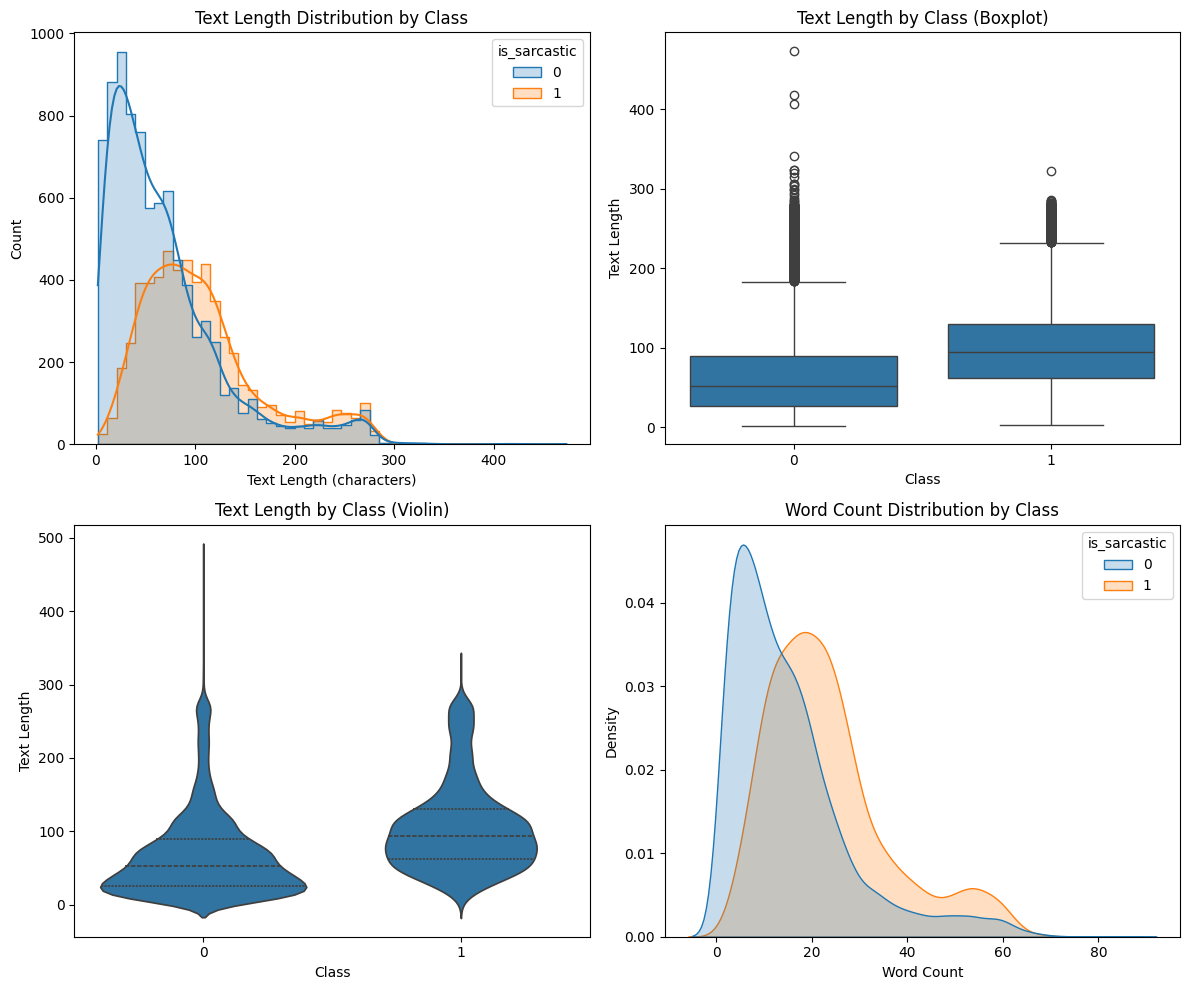

In [64]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

# Assuming df1 has a text column 'text' and target column 'is_sarcastic'
df1['text_length'] = df1['text'].astype(str).str.len()

# 2x2 grid
fig, axes = plt.subplots(2, 2, figsize=(12, 10))

# --- Plot 1: Distribution (histogram + KDE) per class ---
sns.histplot(data=df1, x='text_length', hue='is_sarcastic',
             kde=True, bins=50, element='step', ax=axes[0, 0])
axes[0, 0].set_title('Text Length Distribution by Class')
axes[0, 0].set_xlabel('Text Length (characters)')

# --- Plot 2: Boxplot per class ---
sns.boxplot(data=df1, x='is_sarcastic', y='text_length', ax=axes[0, 1])
axes[0, 1].set_title('Text Length by Class (Boxplot)')
axes[0, 1].set_xlabel('Class')
axes[0, 1].set_ylabel('Text Length')

# --- Plot 3: Violin plot per class ---
sns.violinplot(data=df1, x='is_sarcastic', y='text_length',
               inner='quartile', ax=axes[1, 0])
axes[1, 0].set_title('Text Length by Class (Violin)')
axes[1, 0].set_xlabel('Class')
axes[1, 0].set_ylabel('Text Length')

# --- Plot 4: Word count distribution ---
sns.kdeplot(data=df1, x='word_count', hue='is_sarcastic',
            fill=True, common_norm=False, ax=axes[1, 1])
axes[1, 1].set_title('Word Count Distribution by Class')
axes[1, 1].set_xlabel('Word Count')

plt.tight_layout()
plt.show()

In [65]:
df1.head(2)

,is_sarcastic,text,<smiling_face_with_sunglasses>,<maple_leaf>,<wilted_flower>,<clapping_hands>,<smiling_face_with_smiling_eyes>,<face_with_tears_of_joy>,<grinning_squinting_face>,<face_with_rolling_eyes>,...,<brain>,<ATM_sign>,<coin>,<money_bag>,<white_cane>,.,?,!,word_count,text_length
0,0,نہیں پائین,1,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,2,10
1,0,انساں کو تھکا دیتا ہے سوچوں کا سفر بھی,0,1,1,0,0,0,0,0,...,0,0,0,0,0,3,0,0,9,39


#### Dataset-1: Train/Val/Test Split

In [66]:
y1 = df1['is_sarcastic']
X1 = df1.drop(columns=['is_sarcastic'])

In [67]:
other_columns = X1.drop(columns=['text']).columns.to_list()
len(other_columns)

587

In [68]:
from sklearn.model_selection import train_test_split

# 1. Split off 20% for Val/Test, keep 80% for Training
X1_train, X1_temp, y1_train, y1_temp = train_test_split(
    X1, y1,
    test_size=0.20,
    stratify=y1,       # Ensures sarcasm ratio is preserved
    random_state=42
)

# 2. Split the remaining 20% equally into 10% Validation and 10% Test
X1_val, X1_test, y1_val, y1_test = train_test_split(
    X1_temp, y1_temp,
    test_size=0.50,
    stratify=y1_temp,
    random_state=42
)

print(f"Train: {X1_train.shape[0]} | Val: {X1_val.shape[0]} | Test: {X1_test.shape[0]}")

Train: 11653 | Val: 1457 | Test: 1457


#### *Downloading Corpus1
To train the tokenizer

In [69]:
X1_train['text'].head(2)

,text
6503,یہ صابر شاکر نے ٹھیک پڑھا تھا
6375,ـــــ••ـــــ خدایا لطــفا دلہایمان را به دلے که قسمتماݩ نیست نزدیک نکن قشنگ ترین دعا حرف دل


In [70]:
df.iloc[1319]

,1319
is_sarcastic,1
text,الف سے اچھی گاف سے گڑیا نون سے نانی لوٹ لیا ہے تم لوگوں نے ہر ایک پاکستانی😁


In [71]:
df.iloc[10691]

,10691
is_sarcastic,0
text,جانی میرا پسندیدہ شعر وا تسی زیادتی کی تھوڑی ایسے لکھنا آئیندہ پلیج 😂 ؀ سنو جاناں اکتوبر رہ گیا تھوڑا نومبر آنے والا ہے تیری یادوں کو لیکر پھر دسمبر آنے والا ہے نمود_عشق مجنونیاں


In [72]:
from google.colab import files

text1 = X1_train['text']

with open('corpus1.txt', 'w', encoding='utf-8') as f:
    f.write('\n'.join(text1) + '\n')

# Trigger the browser download
files.download('corpus1.txt')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

#### Dataset-1: Training BPE Tokenizer

In [73]:
# setting up output directories for tokenizers

import os

save_dir = "/content/tokenizers/"   # forward slashes, correct path for Colab
tokenizer1_path = save_dir+"tokenizer1/"
os.makedirs(save_dir, exist_ok=True)
os.makedirs(tokenizer1_path, exist_ok=True)

In [74]:
!pip install tokenizers

In [75]:
from tokenizers import Tokenizer
from tokenizers.models import BPE
from tokenizers.trainers import BpeTrainer
from tokenizers.pre_tokenizers import Whitespace
from tokenizers.processors import TemplateProcessing

corpus_file = "corpus1.txt"

# Initialize the Tokenizer with an empty BPE model
tokenizer = Tokenizer(BPE(unk_token="<unk>"))

# Adding a Pre-tokenizer
# This splits the text into words by whitespace before the BPE merges happen.
tokenizer.pre_tokenizer = Whitespace()

# Configuring the BpeTrainer
# We define the vocabulary size, minimum frequency for a pair to be merged,
# and the special tokens we want to include.
trainer = BpeTrainer(
    vocab_size=10000, # Adjust based on your dataset size
    min_frequency=2,
    special_tokens=[
    "<|endoftext|>",
    "<pad>",
    "<unk>",
    "<user>",
    "<url>",
    "<emphasis>",
    "</emphasis>",
    "<s>",
    "</s>"
]
)

# Training the Tokenizer
print("Training the tokenizer...")
tokenizer.train(files=[corpus_file], trainer=trainer)

# 2. Configure the Post-Processor AFTER training (so the tokenizer knows the IDs of <s> and </s>)
tokenizer.post_processor = TemplateProcessing(
    single="<s> $A </s>",
    pair="<s> $A </s> <s> $B </s>", # Defines how to handle two sentences packed together
    special_tokens=[
        ("<s>", tokenizer.token_to_id("<s>")),
        ("</s>", tokenizer.token_to_id("</s>")),
    ],
)

# Saving the trained tokenizer
output_tokenizer1 = tokenizer1_path+"tokenizer1.json"
tokenizer.save(output_tokenizer1)
print(f"Tokenizer trained and saved to {output_tokenizer1}.\n")

Training the tokenizer...
Tokenizer trained and saved to /content/tokenizers/tokenizer1/tokenizer1.json.



In [76]:
# Testing the tokenizer
loaded_tokenizer_1 = Tokenizer.from_file(output_tokenizer1)

test_sentence = text1[0]
output = loaded_tokenizer_1.encode(test_sentence)

print(f"Original Text: {test_sentence}")
print(f"Tokens: {output.tokens}")
print(f"Token IDs: {output.ids}")

Original Text: نہیں پائین
Tokens: ['<s>', 'نہیں', 'پائین', '</s>']
Token IDs: [7, 391, 4372, 8]


#### Model-1: TF-IDF based Logistic Regression on Dataset-1

In [77]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import f1_score

loaded_tokenizer_1.no_truncation()
loaded_tokenizer_1.no_padding()

def bpe_tokenize(text):
    return loaded_tokenizer_1.encode(text).tokens   # token strings

vectorizer = TfidfVectorizer(
    tokenizer=bpe_tokenize,
    preprocessor=None,
    lowercase=False,       # BPE was trained on preprocessed text
    token_pattern=None,    # silences the warning, since a custom tokenizer is used
    ngram_range=(1, 2),
    min_df=3,
    sublinear_tf=True,
)

In [78]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import MaxAbsScaler

ct = ColumnTransformer(
    [("tfidf", vectorizer, "text")],
    remainder="passthrough",       # all other columns kept as-is
    sparse_threshold=1.0,          # keep the output sparse
)

X1_train = ct.fit_transform(X1_train)
X1_val   = ct.transform(X1_val)
X1_test  = ct.transform(X1_test)

In [79]:
clf = LogisticRegression(solver="liblinear", C=1, class_weight="balanced", max_iter=1000)
clf.fit(X1_train, y1_train)
print(f1_score(y1_val, clf.predict(X1_val)))

0.7944760357432982


##### Evaluation

Accuracy : 0.7927247769389156
Precision: 0.7975218538905647
Recall   : 0.7927247769389156
F1       : 0.7939499145538718
              precision    recall  f1-score   support

           0     0.8481    0.7933    0.8198       866
           1     0.7233    0.7919    0.7561       591

    accuracy                         0.7927      1457
   macro avg     0.7857    0.7926    0.7879      1457
weighted avg     0.7975    0.7927    0.7939      1457



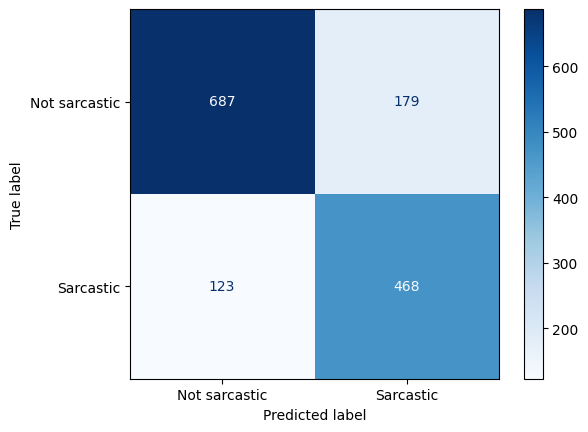

In [80]:
# evaluating
from sklearn.metrics import (
    confusion_matrix, ConfusionMatrixDisplay,
    classification_report, f1_score, precision_score, recall_score, accuracy_score
)
import matplotlib.pyplot as plt

y_pred = clf.predict(X1_test)

# Weighted metrics
print("Accuracy :", accuracy_score(y1_test, y_pred))
print("Precision:", precision_score(y1_test, y_pred, average="weighted"))
print("Recall   :", recall_score(y1_test, y_pred, average="weighted"))
print("F1       :", f1_score(y1_test, y_pred, average="weighted"))

# Per-class and weighted-average report
print(classification_report(y1_test, y_pred, digits=4))

# Confusion matrix
cm = confusion_matrix(y1_test, y_pred)
ConfusionMatrixDisplay(cm, display_labels=["Not sarcastic", "Sarcastic"]).plot(cmap="Blues", values_format="d")
plt.show()

#### Model-2: SVM

In [81]:

from sklearn.svm import LinearSVC
from sklearn.metrics import f1_score

best_svm = None
best_f1 = -1
best_C = None

for C in [0.01, 0.1, 0.5, 1, 5, 10]:
    svm = LinearSVC(
        C=C,
        class_weight="balanced",
        max_iter=100000,
        dual=False,
        random_state=42
    )
    svm.fit(X1_train, y1_train)

    y_pred = svm.predict(X1_val)
    f1 = f1_score(y1_val, y_pred, average="weighted")

    print(f"C={C}, Weighted F1={f1:.4f}")
    print("Iterations used:", svm.n_iter_)

    if f1 > best_f1:
        best_f1 = f1
        best_svm = svm
        best_C = C

print(f"\nBest C: {best_C}")
print(f"Best validation F1: {best_f1:.4f}")

C=0.01, Weighted F1=0.7730
Iterations used: 14
C=0.1, Weighted F1=0.8259
Iterations used: 38
C=0.5, Weighted F1=0.8245
Iterations used: 212
C=1, Weighted F1=0.8177
Iterations used: 326
C=5, Weighted F1=0.8002
Iterations used: 481
C=10, Weighted F1=0.8015
Iterations used: 559

Best C: 0.1
Best validation F1: 0.8259


##### Evaluation

Accuracy : 0.7927247769389156
Precision: 0.7975218538905647
Recall   : 0.7927247769389156
F1       : 0.7939499145538718
              precision    recall  f1-score   support

           0     0.8481    0.7933    0.8198       866
           1     0.7233    0.7919    0.7561       591

    accuracy                         0.7927      1457
   macro avg     0.7857    0.7926    0.7879      1457
weighted avg     0.7975    0.7927    0.7939      1457



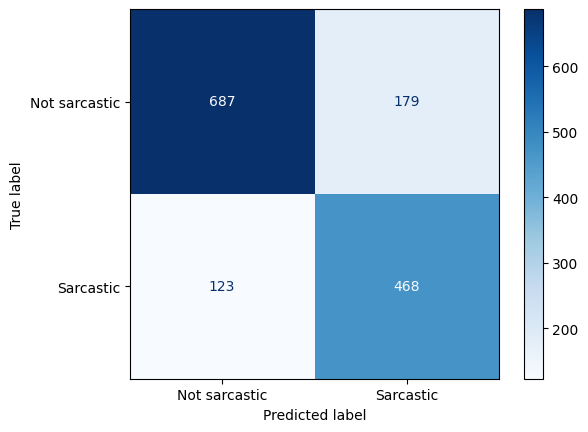

In [82]:
y_pred = best_svm.predict(X1_test)

# Weighted metrics
print("Accuracy :", accuracy_score(y1_test, y_pred))
print("Precision:", precision_score(y1_test, y_pred, average="weighted"))
print("Recall   :", recall_score(y1_test, y_pred, average="weighted"))
print("F1       :", f1_score(y1_test, y_pred, average="weighted"))

# Per-class and weighted-average report
print(classification_report(y1_test, y_pred, digits=4))

# Confusion matrix
cm = confusion_matrix(y1_test, y_pred)
ConfusionMatrixDisplay(cm, display_labels=["Not sarcastic", "Sarcastic"]).plot(cmap="Blues", values_format="d")
plt.show()

### ix. Dataset-2 (emojis demojized and only punctuations as a separate individual features)

Contains the following columns:

* `is_sarcastic`
* `word_count` - added after preprocessing
* `text`
  * contains no punctuation (the important ones are separated into their own columns)
  * contains demojized emojis i.e. laughing emoji converted into \<laughing emoji\> tag using `emoji` library

And the following three columns include the count of each element in a row:

* `!`
* `?`
* `.`

In [83]:
df2 = df.copy()

# Apply Punctuation extraction on the emoji-cleaned text (or original text)
df2["cleaned_text"], df2["punctuations"] = zip(
    *df2["text"].apply(text_preprocessing_pipeline)
)

# Dropping the uncleaned `text` column
df2.drop(columns='text', inplace=True)
# Renaming `cleaned_text` to `text`
df2 = df2.rename(columns={'cleaned_text': 'text'})

# adding a new feature "word-count"
df2['word_count'] = df2['text'].str.split().str.len().fillna(0).astype(int)

# output
df2.columns

Index(['is_sarcastic', 'text', 'punctuations', 'word_count'], dtype='object')

In [84]:
df2 = expand_element_counts(df2, 'punctuations')
df2.drop(columns=['punctuations'], inplace = True)
df2.columns

Index(['is_sarcastic', 'text', 'word_count', '.', '?', '!'], dtype='object')

In [85]:
df2.head(2)

,is_sarcastic,text,word_count,.,?,!
0,0,نہیں پائین <smilingfacewithsunglasses>,3,0,0,0
1,0,انساں کو تھکا دیتا ہے سوچوں کا سفر بھی <mapleleaf> <wiltedflower>,11,3,0,0


In [86]:
# Confirming that no hashtags are remaining

# Filter rows where the 'text' column contains a hashtag
hashtag_rows_df2 = df2[df2["text"].str.contains("#", na=False)]

# See how many rows have hashtags
print(f"Total rows with hashtags: {len(hashtag_rows_df2)}")

Total rows with hashtags: 0


#### Word Count Statistics

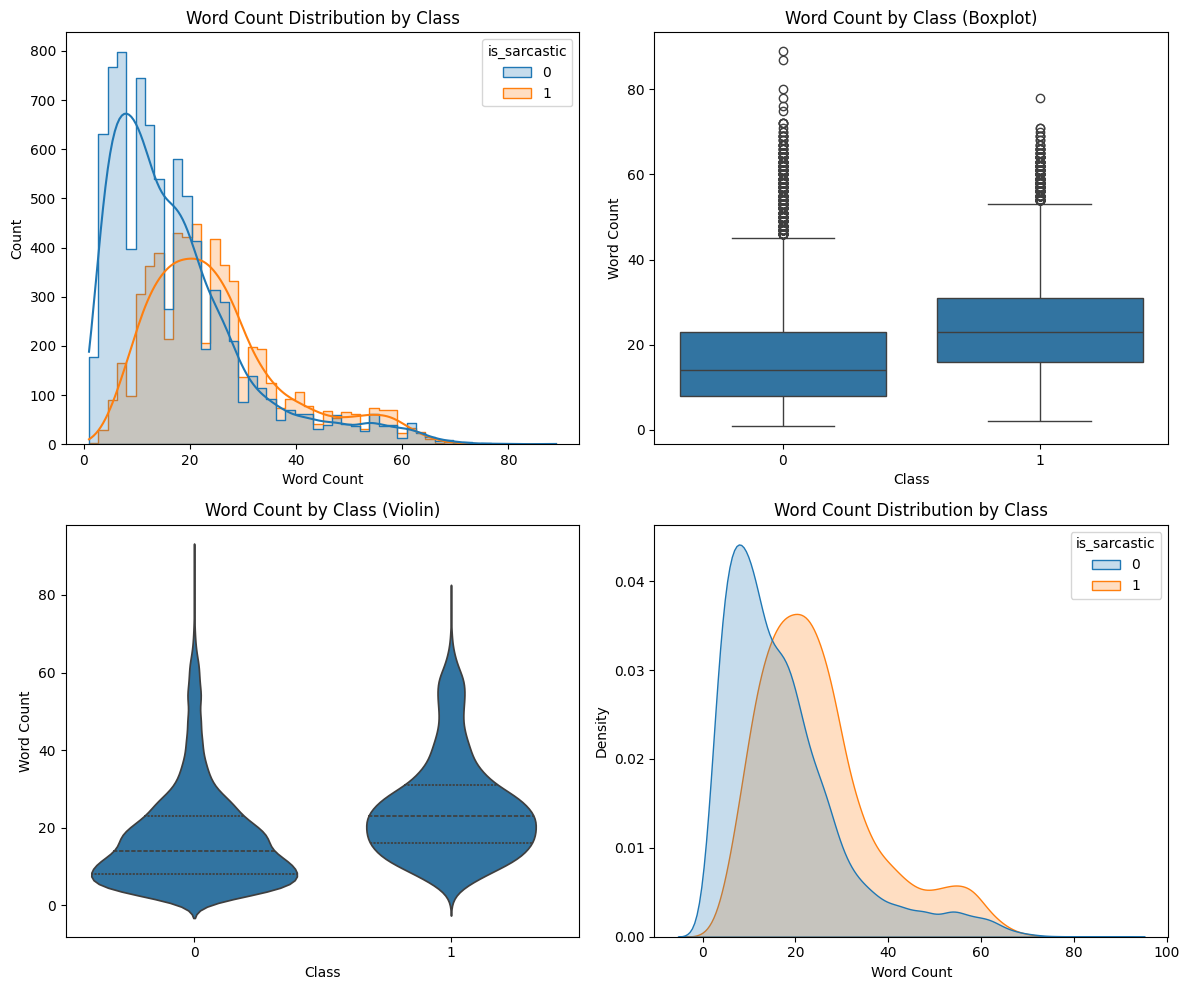

In [87]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

# 2x2 grid
fig, axes = plt.subplots(2, 2, figsize=(12, 10))

# --- Plot 1: Distribution (histogram + KDE) per class ---
sns.histplot(data=df2, x='word_count', hue='is_sarcastic',
             kde=True, bins=50, element='step', ax=axes[0, 0])
axes[0, 0].set_title('Word Count Distribution by Class')
axes[0, 0].set_xlabel('Word Count')

# --- Plot 2: Boxplot per class ---
sns.boxplot(data=df2, x='is_sarcastic', y='word_count', ax=axes[0, 1])
axes[0, 1].set_title('Word Count by Class (Boxplot)')
axes[0, 1].set_xlabel('Class')
axes[0, 1].set_ylabel('Word Count')

# --- Plot 3: Violin plot per class ---
sns.violinplot(data=df2, x='is_sarcastic', y='word_count',
               inner='quartile', ax=axes[1, 0])
axes[1, 0].set_title('Word Count by Class (Violin)')
axes[1, 0].set_xlabel('Class')
axes[1, 0].set_ylabel('Word Count')

# --- Plot 4: Word count distribution ---
sns.kdeplot(data=df2, x='word_count', hue='is_sarcastic',
            fill=True, common_norm=False, ax=axes[1, 1])
axes[1, 1].set_title('Word Count Distribution by Class')
axes[1, 1].set_xlabel('Word Count')

plt.tight_layout()
plt.show()

#### Dataset-2: Train/Val/Test Split

In [88]:
y2 = df2['is_sarcastic']
X2 = df2.drop(columns=['is_sarcastic'])

In [89]:
# . Split off 20% for Val/Test, keep 80% for Training
X2_train, X2_temp, y2_train, y2_temp = train_test_split(
    X2, y2,
    test_size=0.20,
    stratify=y2,       # Ensures sarcasm ratio is preserved
    random_state=42
)

# 2. Split the remaining 20% equally into 10% Validation and 10% Test
X2_val, X2_test, y2_val, y2_test = train_test_split(
    X2_temp, y2_temp,
    test_size=0.50,
    stratify=y2_temp,
    random_state=42
)

print(f"Train: {X2_train.shape[0]} | Val: {X2_val.shape[0]} | Test: {X2_test.shape[0]}")

Train: 11653 | Val: 1457 | Test: 1457


#### *Downloading Corpus2

In [90]:
text2 = X2_train['text']

with open('corpus2.txt', 'w', encoding='utf-8') as f:
    f.write('\n'.join(text2) + '\n')

# Trigger the browser download
files.download('corpus2.txt')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

#### Dataset-2: Training BPE Tokenizer2

In [91]:
tokenizer2_path = save_dir+"tokenizer2/"
os.makedirs(tokenizer2_path, exist_ok=True)

In [92]:
from tokenizers.pre_tokenizers import WhitespaceSplit

corpus_file = "corpus2.txt"

special_tokens=[
    "<|endoftext|>",
    "<pad>",
    "<unk>",
    "<user>",
    "<url>",
    "<emphasis>",
    "</emphasis>",
    '<s>',
    '</s>'
]

# Initialize the Tokenizer with an empty BPE model
tokenizer2 = Tokenizer(BPE(unk_token="<unk>"))

# So the tokenizer NEVER splits these specific strings
tokenizer2.add_special_tokens(special_tokens+emoji_list)

# Adding a Pre-tokenizer
# This splits the text into words by whitespace before the BPE merges happen.
tokenizer2.pre_tokenizer = WhitespaceSplit()

# Configuring the BpeTrainer
# We define the vocabulary size, minimum frequency for a pair to be merged,
# and the special tokens we want to include.
trainer = BpeTrainer(
    vocab_size=10000, # Adjust based on your dataset size
    min_frequency=2,
    special_tokens=special_tokens+emoji_list
)

# Training the Tokenizer
print("Training the tokenizer...")
tokenizer2.train(files=[corpus_file], trainer=trainer)

# Configure the Post-Processor AFTER training (so the tokenizer knows the IDs of <s> and </s>)
tokenizer2.post_processor = TemplateProcessing(
    single="<s> $A </s>",
    pair="<s> $A </s> <s> $B </s>", # Defines how to handle two sentences packed together
    special_tokens=[
        ("<s>", tokenizer2.token_to_id("<s>")),
        ("</s>", tokenizer2.token_to_id("</s>")),
    ],
)

# Saving the trained tokenizer
output_tokenizer2 = tokenizer2_path+"tokenizer2.json"
tokenizer2.save(output_tokenizer2)
print(f"Tokenizer trained and saved to {output_tokenizer2}.\n")

Training the tokenizer...
Tokenizer trained and saved to /content/tokenizers/tokenizer2/tokenizer2.json.



In [93]:
# Testing the tokenizer
loaded_tokenizer_2 = Tokenizer.from_file(output_tokenizer2)

test_sentence = text2[0]
output = loaded_tokenizer_2.encode(test_sentence)

print(f"Original Text: {test_sentence}")
print(f"Tokens: {output.tokens}")
print(f"Token IDs: {output.ids}")

Original Text: نہیں پائین <smilingfacewithsunglasses>
Tokens: ['<s>', 'نہیں', 'پائین', '<smilingfacewithsunglasses>', '</s>']
Token IDs: [7, 997, 5751, 1751, 8]


#### Model-3: TF-IDF based Logistic Regression on Dataset-2

In [94]:
loaded_tokenizer_2.no_truncation()
loaded_tokenizer_2.no_padding()

def bpe_tokenize(text):
    return loaded_tokenizer_2.encode(text).tokens   # token strings

vectorizer = TfidfVectorizer(
    tokenizer=bpe_tokenize,
    preprocessor=None,
    lowercase=False,       # BPE was trained on preprocessed text
    token_pattern=None,    # silences the warning, since a custom tokenizer is used
    ngram_range=(1, 2),
    min_df=3,
    sublinear_tf=True,
)

In [95]:
ct = ColumnTransformer(
    [("tfidf", vectorizer, "text")],
    remainder="passthrough",       # all other columns kept as-is
    sparse_threshold=1.0,          # keep the output sparse
)

X2_train = ct.fit_transform(X2_train)
X2_val   = ct.transform(X2_val)
X2_test  = ct.transform(X2_test)

In [96]:
clf = LogisticRegression(solver="liblinear", C=1, class_weight="balanced", max_iter=1000)
clf.fit(X2_train, y2_train)
print(f1_score(y2_val, clf.predict(X2_val)))

0.7798845836768343


##### Evaluation

Accuracy : 0.8050789293067948
Precision: 0.8076927176512021
Recall   : 0.8050789293067948
F2       : 0.8058907984842684
              precision    recall  f1-score   support

           0     0.8506    0.8152    0.8325       866
           1     0.7448    0.7902    0.7668       591

    accuracy                         0.8051      1457
   macro avg     0.7977    0.8027    0.7997      1457
weighted avg     0.8077    0.8051    0.8059      1457



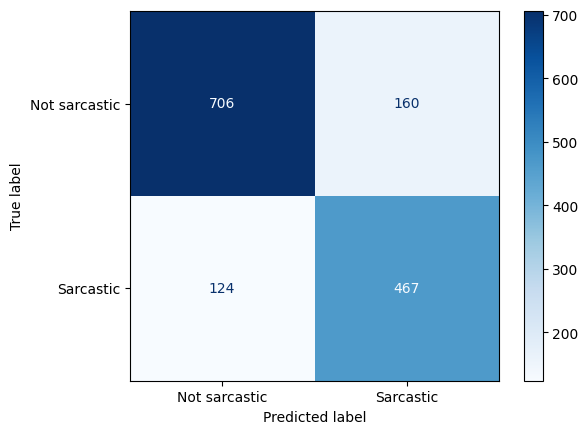

In [97]:
# evaluating
y_pred = clf.predict(X2_test)

# Weighted metrics
print("Accuracy :", accuracy_score(y2_test, y_pred))
print("Precision:", precision_score(y2_test, y_pred, average="weighted"))
print("Recall   :", recall_score(y2_test, y_pred, average="weighted"))
print("F2       :", f1_score(y2_test, y_pred, average="weighted"))

# Per-class and weighted-average report
print(classification_report(y2_test, y_pred, digits=4))

# Confusion matrix
cm = confusion_matrix(y2_test, y_pred)
ConfusionMatrixDisplay(cm, display_labels=["Not sarcastic", "Sarcastic"]).plot(cmap="Blues", values_format="d")
plt.show()

#### Model-4: SVM

In [98]:
best_svm = None
best_f1 = -1
best_C = None

for C in [0.01, 0.1, 0.5, 1, 5, 10]:
    svm = LinearSVC(
        C=C,
        class_weight="balanced",
        max_iter=100000,
        dual=False,
        random_state=42
    )
    svm.fit(X2_train, y2_train)

    y_pred = svm.predict(X2_val)
    f1 = f1_score(y2_val, y_pred, average="weighted")

    print(f"C={C}, Weighted F1={f1:.4f}")
    print("Iterations used:", svm.n_iter_)

    if f1 > best_f1:
        best_f1 = f1
        best_svm = svm
        best_C = C

print(f"\nBest C: {best_C}")
print(f"Best validation F1: {best_f1:.4f}")

C=0.01, Weighted F1=0.7685
Iterations used: 12
C=0.1, Weighted F1=0.8155
Iterations used: 18
C=0.5, Weighted F1=0.8086
Iterations used: 21
C=1, Weighted F1=0.8078
Iterations used: 22
C=5, Weighted F1=0.7987
Iterations used: 31
C=10, Weighted F1=0.7911
Iterations used: 42

Best C: 0.1
Best validation F1: 0.8155


##### Evaluation

Accuracy : 0.8050789293067948
Precision: 0.8080723564271723
Recall   : 0.8050789293067948
F1       : 0.8059650952946708
              precision    recall  f1-score   support

           0     0.8523    0.8129    0.8322       866
           1     0.7433    0.7936    0.7676       591

    accuracy                         0.8051      1457
   macro avg     0.7978    0.8033    0.7999      1457
weighted avg     0.8081    0.8051    0.8060      1457



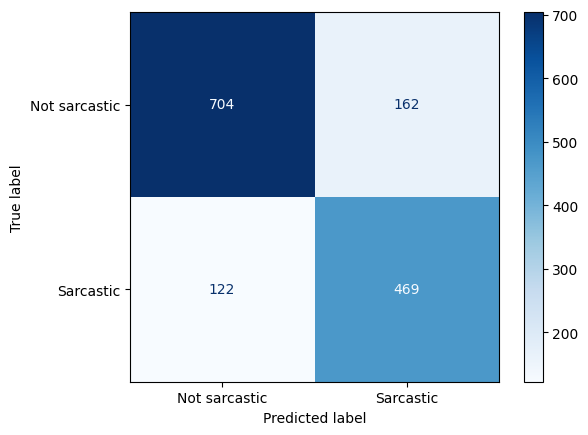

In [99]:
y_pred = best_svm.predict(X2_test)

# Weighted metrics
print("Accuracy :", accuracy_score(y2_test, y_pred))
print("Precision:", precision_score(y2_test, y_pred, average="weighted"))
print("Recall   :", recall_score(y2_test, y_pred, average="weighted"))
print("F1       :", f1_score(y2_test, y_pred, average="weighted"))

# Per-class and weighted-average report
print(classification_report(y2_test, y_pred, digits=4))

# Confusion matrix
cm = confusion_matrix(y2_test, y_pred)
ConfusionMatrixDisplay(cm, display_labels=["Not sarcastic", "Sarcastic"]).plot(cmap="Blues", values_format="d")
plt.show()

#### Model-5: BiLSTM

In [102]:
print("hw")

hw


### x. Model-6: XLM-RoBERTa

### xi. Downloading Both Tokenizers

In [100]:
!zip -r /content/tokenizers.zip /content/tokenizers

  adding: content/tokenizers/ (stored 0%)
  adding: content/tokenizers/tokenizer2/ (stored 0%)
  adding: content/tokenizers/tokenizer2/tokenizer2.json (deflated 84%)
  adding: content/tokenizers/tokenizer1/ (stored 0%)
  adding: content/tokenizers/tokenizer1/tokenizer1.json (deflated 83%)


In [101]:
files.download('/content/tokenizers.zip')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>